# ExplainMaint — Notebook reproductible
**ENSI, Challenge 1 · Cas 15 : Maintenance prédictive AI4I 2020.** Le notebook importe le même code métier que Streamlit/FastAPI : pas de pipeline parallèle divergent.

Le dataset UCI est synthétique ; les scores sont mesurés par ce notebook lorsqu’il est exécuté. Les colonnes TWF/HDF/PWF/OSF/RNF sont exclues pour éviter la fuite de cible.

Installer `requirements-dev.txt`, puis exécuter toutes les cellules avec le noyau Python du projet. Les sorties de cette validation sont enregistrées séparément dans `results/validation_2026-10-13/` ; `one_pager_final.pdf` et les captures historiques sont conservés. Les chiffres d’une nouvelle exécution peuvent différer de ces documents.

In [1]:
import sys
import os
import json
import hashlib
import platform
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core.py").is_file())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / "results" / "validation_2026-10-13"
OUTPUT.mkdir(parents=True, exist_ok=True)
from core import load_uci, prepare_binary, DEFAULT_FEATURES, TARGET, train_compare, threshold_metrics, model_importance, permutation_table, global_explain
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
print("Python", platform.python_version())
packages = {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "xgboost", "shap", "lime", "fastapi"]}
display(pd.Series(packages, name="Version exécutée"))

Python 3.11.7


numpy             2.4.6
pandas            2.3.3
scikit-learn      1.9.1
xgboost           3.2.0
shap             0.51.0
lime            0.2.0.1
fastapi         0.143.0
Name: Version exécutée, dtype: object

## 1. Téléchargement et audit des données
La fonction de téléchargement essaye successivement `ucimlrepo`, le ZIP officiel et un miroir ; copie locale réutilisable.

In [2]:
df = load_uci()
print("Forme :", df.shape)
display(df.head())
display(df.isna().sum().rename("Manquants").to_frame())
display(df[TARGET].value_counts(normalize=True).rename("Proportion"))

Forme : (10000, 12)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,Manquants
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0
HDF,0
PWF,0


Machine failure
0    0.9661
1    0.0339
Name: Proportion, dtype: float64

In [3]:
display(df[list(DEFAULT_FEATURES)].describe(include="all"))
print("Exclusions de fuite : TWF, HDF, PWF, OSF, RNF, UDI, Product ID")
display(df[list(DEFAULT_FEATURES)].select_dtypes(include="number").corr())

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,3,NaN,NaN,NaN,NaN,NaN
top,L,NaN,NaN,NaN,NaN,NaN
freq,6000,NaN,NaN,NaN,NaN,NaN
mean,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000
std,NaN,2.000259,1.483734,179.284096,9.968934,63.654147
min,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000
25%,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000
50%,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000
75%,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000


Exclusions de fuite : TWF, HDF, PWF, OSF, RNF, UDI, Product ID


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000


## 2. Prétraitement sans fuite et échantillons stratifiés

In [4]:
X, y = prepare_binary(df, TARGET, DEFAULT_FEATURES, "1")
print("Classes", y.value_counts().to_dict())

Classes {0: 9661, 1: 339}


## 3. Comparaison des cinq modèles
Optimisation facultative dans le notebook : mettre `tune=True` pour 3 plis et 4 configurations aléatoires par modèle.

In [5]:
models = ["Régression logistique", "Arbre de décision", "KNN", "Random Forest", "XGBoost"]
params = {"trees":130, "depth":5, "neighbors":7, "C":1., "lr":.07}
run = train_compare(X, y, models, test_size=.25, params=params, tune=False)
scores = pd.DataFrame(run["scores"]).T.sort_values("PR-AUC (AP)",ascending=False)
display(scores)
scores.to_csv(OUTPUT / "comparaison_modeles.csv", index_label="Modèle", encoding="utf-8-sig")

,AUC-ROC,PR-AUC (AP),Précision,Rappel,F1
XGBoost,0.9766,0.7764,0.5113,0.8000,0.6239
Random Forest,0.9704,0.6306,0.5385,0.7412,0.6238
Arbre de décision,0.9227,0.5194,0.3020,0.9059,0.4529
KNN,0.8554,0.5107,0.8000,0.2824,0.4174
Régression logistique,0.8836,0.3833,0.1393,0.8000,0.2373


## 4. ROC, précision-rappel, matrice de confusion et seuil

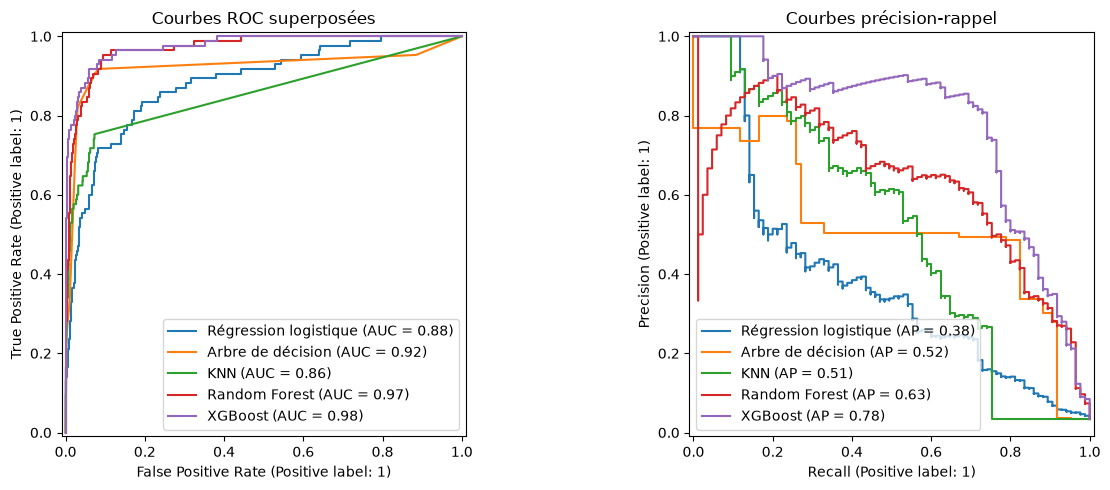

,Seuil,AUC-ROC,PR-AUC (AP),Précision,Rappel,F1
0,0.30,0.9766,0.7764,0.3846,0.8824,0.5357
1,0.35,0.9766,0.7764,0.4229,0.8706,0.5692
2,0.50,0.9766,0.7764,0.5113,0.8000,0.6239


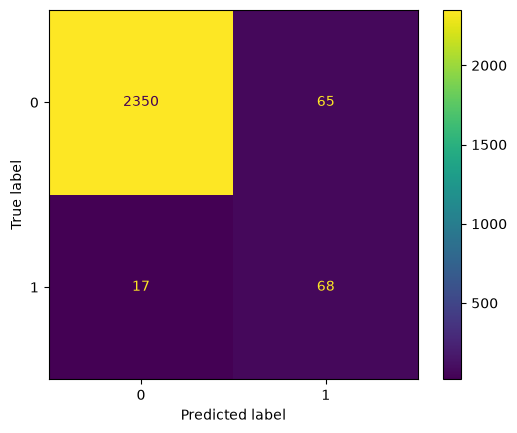

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in run["probs"].items():
    RocCurveDisplay.from_predictions(run["y_test"], prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(run["y_test"], prob, name=name, ax=axes[1])
axes[0].set_title("Courbes ROC superposées")
axes[1].set_title("Courbes précision-rappel")
fig.tight_layout()
plt.show()
selected = scores.index[0]
threshold = .50
thresholds = pd.DataFrame([dict(Seuil=t, **threshold_metrics(run["y_test"], run["probs"][selected], t)) for t in [.30, .35, .50]])
display(thresholds)
thresholds.to_csv(OUTPUT / "comparaison_seuils.csv", index=False, encoding="utf-8-sig")
ConfusionMatrixDisplay.from_predictions(run["y_test"], (run["probs"][selected] >= threshold).astype(int))
plt.show()

## 5. Explicabilité globale, individuelle SHAP + LIME
La même fonction `local_explain` alimente l’API et l’application. Les perturbations s’effectuent en espace encodé. Elles peuvent produire des combinaisons d’indicateurs one-hot absentes des données ; ces explications restent approximatives, descriptives et non causales.

In [7]:
from core import local_explain
bundle = {"pipeline":run["models"][selected], "background":run["X_train"].sample(min(120,len(run["X_train"])),random_state=42), "features":list(X), "name":selected}
display(model_importance(bundle).head(12))
display(permutation_table(bundle,run["X_test"],run["y_test"]))

,Variable,Importance
3,num__Torque [Nm],0.268573
2,num__Rotational speed [rpm],0.266952
4,num__Tool wear [min],0.199665
0,num__Air temperature [K],0.092875
1,num__Process temperature [K],0.058476
6,cat__Type_L,0.048579
7,cat__Type_M,0.043429
5,cat__Type_H,0.021451


,Variable,Importance AP,Ecart-type
4,Torque [Nm],0.503428,0.004763
3,Rotational speed [rpm],0.302206,0.021644
1,Air temperature [K],0.275864,0.040485
2,Process temperature [K],0.252464,0.102011
5,Tool wear [min],0.199051,0.005276
0,Type,0.017550,0.012204


C:\Users\Admin\Downloads\ExplainMaint_AI4I_MAJ_Depot\ExplainMaint_AI4I\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PermutationExplainer explainer:   5%|▌         | 1/20 [00:00<?, ?it/s]

PermutationExplainer explainer: 21it [00:21,  1.06s/it]               

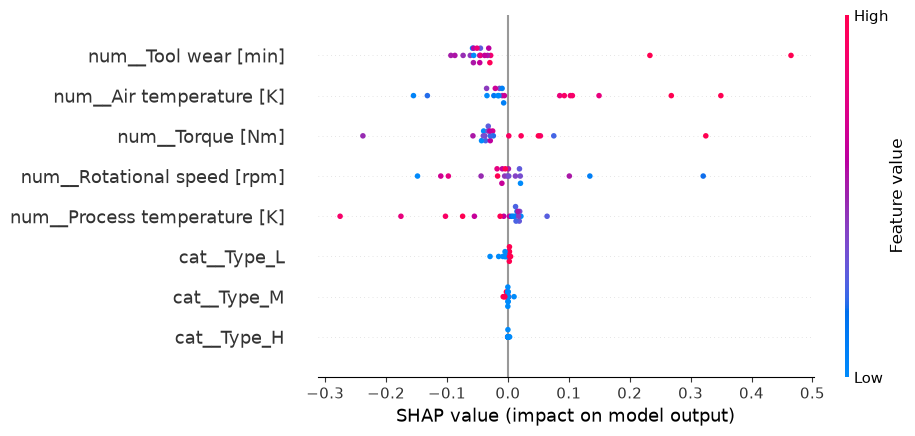

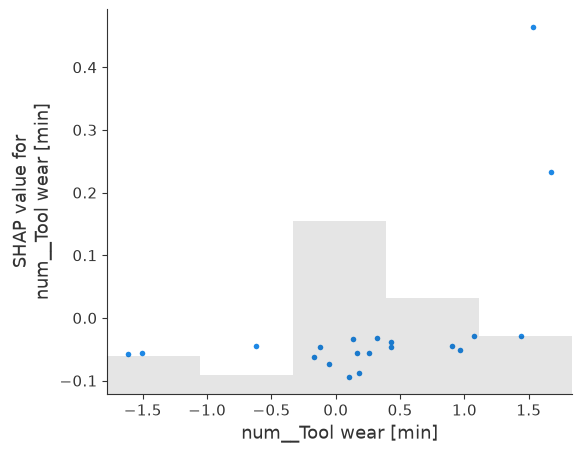

In [8]:
import shap
global_values = global_explain(bundle, n=20)
ex = shap.Explanation(values=np.asarray(global_values["values"]), base_values=np.asarray(global_values["base_values"]), data=np.asarray(global_values["data"]), feature_names=global_values["names"])
shap.plots.beeswarm(ex, max_display=12, show=False)
plt.gcf().savefig(OUTPUT / "shap_global_beeswarm.png", dpi=160, bbox_inches="tight")
plt.show()
shap.plots.scatter(ex[:, int(np.abs(ex.values).mean(axis=0).argmax())], show=False)
plt.gcf().savefig(OUTPUT / "shap_dependance.png", dpi=160, bbox_inches="tight")
plt.show()

Le modèle estime un risque de panne de 2.4%. Les facteurs qui augmentent ce risque sont : Process temperature [K]. 
Probabilité 0.023978015407919884
Décision au seuil 0.5 : 0


,variable,weight
0,num__Torque [Nm],0.077511
1,num__Tool wear [min],0.065748
2,num__Air temperature [K],0.061446
3,num__Rotational speed [rpm],-0.040312
4,cat__Type_L,0.014785
5,num__Process temperature [K],-0.012548
6,cat__Type_H,-0.004910
7,cat__Type_M,0.002443


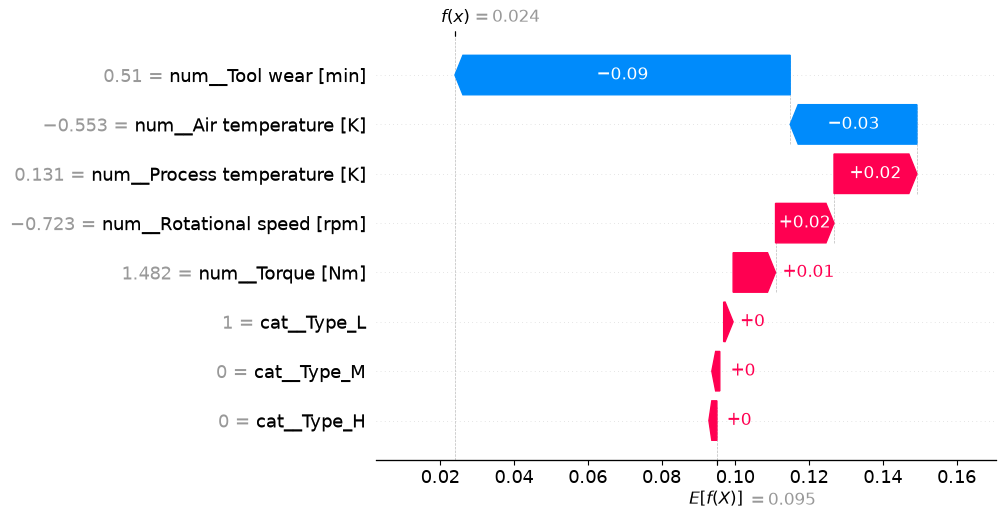

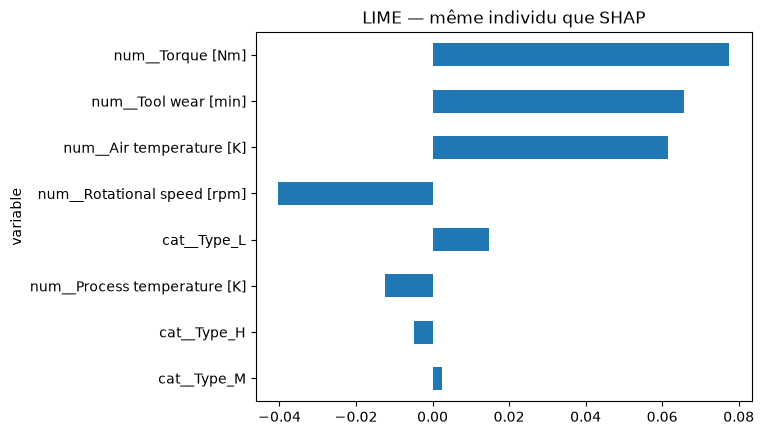

2111

In [9]:
instance = run["X_test"].iloc[0].to_dict()
local = local_explain(bundle, instance)
print(local["summary"], "\nProbabilité", local["probability"])
print("Décision au seuil", threshold, ":", int(local["probability"] >= threshold))
assert np.isclose(local["base_value"] + sum(local["shap_values"]), local["probability"], atol=1e-5), "Échec d’additivité SHAP"
display(pd.DataFrame(local["lime"]))
shap.plots.waterfall(shap.Explanation(values=np.asarray(local["shap_values"]), base_values=local["base_value"], data=np.asarray(local["encoded_values"]), feature_names=local["names"]))
pd.DataFrame(local["lime"]).iloc[::-1].plot.barh(x="variable", y="weight", title="LIME — même individu que SHAP", legend=False)
plt.show()
(OUTPUT / "explication_locale.json").write_text(json.dumps({"record": instance, "threshold": threshold, **local}, ensure_ascii=False, indent=2), encoding="utf-8")

## 6. API FastAPI : validation du modèle entraîné
Le client de test appelle les vraies routes `/health`, `/model`, `/global`, `/explain` et `/openapi.json`. Un artefact temporaire isole cette validation du modèle actif de l’application. SHAP et LIME sont réellement calculés ; ce contrôle en processus ne prouve pas un déploiement public.

In [10]:
from tempfile import TemporaryDirectory
from unittest.mock import patch
from fastapi.testclient import TestClient
import core
import api
with TemporaryDirectory(prefix="explainmaint-notebook-") as temp_dir:
    temp_artifact = Path(temp_dir) / "active_bundle.joblib"
    with patch.object(core, "ARTIFACT", temp_artifact), patch.object(api, "ARTIFACT", temp_artifact):
        core.store_bundle(run["models"][selected], run["X_train"], list(X), selected)
        with TestClient(api.app) as client:
            statuses = {route: client.get(route).status_code for route in ["/health", "/model", "/global?n=2", "/docs", "/openapi.json"]}
            assert all(code == 200 for code in statuses.values()), statuses
            assert client.get("/health").json()["trained_model_available"] is True
            assert client.get("/model").json()["name"] == selected
            response = client.post("/explain", json={"record": instance, "threshold": threshold})
            response.raise_for_status()
            api_result = response.json()
            assert np.isclose(api_result["probability"], local["probability"], atol=1e-8)
            assert api_result["decision"] == int(local["probability"] >= threshold)
            assert api_result["lime"] and api_result["shap_values"]
            assert client.post("/explain", json={"record": {}, "threshold": threshold}).status_code == 422
            statuses["POST /explain"] = response.status_code
display(pd.Series(statuses, name="Statut HTTP en processus"))
(OUTPUT / "api_validation.json").write_text(json.dumps({"transport": "TestClient in-process, no public deployment", "statuses": statuses, "model": selected, "probability": api_result["probability"], "decision": api_result["decision"]}, ensure_ascii=False, indent=2), encoding="utf-8")

C:\Users\Admin\Downloads\ExplainMaint_AI4I_MAJ_Depot\ExplainMaint_AI4I\.venv\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


/health          200
/model           200
/global?n=2      200
/docs            200
/openapi.json    200
POST /explain    200
Name: Statut HTTP en processus, dtype: int64

295

## Synthèse : export distinct avec chiffres réellement mesurés
Le modèle est choisi par AP sur le test pour cette démonstration : une vraie sélection rigoureuse nécessiterait validation indépendante.

In [11]:
from report import create_onepager
import numpy as np
measured = threshold_metrics(run["y_test"], run["probs"][selected], threshold)
weights = np.mean(np.abs(np.array(global_values["values"])),axis=0)
top_names = [global_values["names"][i] for i in np.argsort(-weights)[:4]]
content = create_onepager(selected, measured, len(df), float(y.mean()), threshold, top_names)
out = OUTPUT / "one_pager_resultats_mesures.pdf"
out.write_bytes(content)
print("Rapport créé :",out)
metadata = {"executed_at_utc": datetime.now(timezone.utc).isoformat(), "python": platform.python_version(), "packages": packages, "rows": len(df), "positive_count": int(y.sum()), "features": list(X.columns), "train_rows": len(run["X_train"]), "test_rows": len(run["X_test"]), "test_size": .25, "seed": 42, "hyperparameters": params, "tune": False, "selected_model": selected, "selection": "Descriptive: maximum AP on test; independent validation required", "threshold": threshold, "dataset_sha256": hashlib.sha256((ROOT / "data" / "ai4i2020.csv").read_bytes()).hexdigest()}
(OUTPUT / "execution_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")

Rapport créé : C:\Users\Admin\Downloads\ExplainMaint_AI4I_MAJ_Depot\ExplainMaint_AI4I\results\validation_2026-10-13\one_pager_resultats_mesures.pdf


902

### Discussion
- Confronter variables dominantes et contraintes industrielles ; inspecter divergences SHAP/LIME.
- Dans le dataset principal, pas de variable personnelle sensible explicite ; pour un CSV externe, vérifier équité, proxies et fuite.
- Choisir XGBoost si le gain AP/rappel justifie la complexité ; privilégier la régression logistique si le niveau de transparence exigé domine.
- Données synthétiques, découpage aléatoire, diagnostic non causal : ne pas extrapoler à une exploitation industrielle réelle.